In [1]:
from forecast import load_prices, train_test_split_time, seasonal_naive_forecast, gradient_boosting_forecast, mae
from battery import optimize_schedule, rule_based_schedule, schedule_revenue

prices = load_prices()
train, test = train_test_split_time(prices, test_weeks=8)
test_prices = test["price_eur_mwh"]

# Forecast error: same baseline-vs-model comparison as notebooks 02 and 03, brought
# together here as the starting point of the final story.
baseline_forecast = seasonal_naive_forecast(prices).loc[test.index]
gbm_forecast, gbm_model = gradient_boosting_forecast(prices, test_weeks=8)

baseline_mae = mae(test_prices, baseline_forecast)
gbm_mae = mae(test_prices, gbm_forecast)

print(f"Seasonal-naive baseline MAE: {baseline_mae:.2f} EUR/MWh")
print(f"Gradient boosting MAE:       {gbm_mae:.2f} EUR/MWh")
print(f"Forecast improvement:        {100 * (baseline_mae - gbm_mae) / baseline_mae:.1f}%")

Seasonal-naive baseline MAE: 53.53 EUR/MWh
Gradient boosting MAE:       41.19 EUR/MWh
Forecast improvement:        23.0%


In [2]:
# The question a better forecast actually needs to answer: does it make more money?
# Three strategies, same battery physics, same realized prices to score against:
#  1. Rule-based: no model at all, a fixed daily schedule.
#  2. Forecast-driven: the LP optimizes against the GBM's PREDICTIONS (not knowing the
#     future for real), then that schedule is scored against what actually happened -
#     this is the realistic number: what you'd actually earn running this in production.
#  3. Perfect foresight: the LP optimizes against the ACTUAL prices directly - a ceiling
#     no real, forecast-driven strategy could ever reach, since nobody truly knows
#     tomorrow's prices in advance.
rule_schedule = rule_based_schedule(test_prices)
forecast_schedule = optimize_schedule(gbm_forecast)
perfect_schedule = optimize_schedule(test_prices)

rule_revenue = schedule_revenue(rule_schedule, test_prices)
forecast_driven_revenue = schedule_revenue(forecast_schedule, test_prices)
perfect_revenue = schedule_revenue(perfect_schedule, test_prices)

print(f"Rule-based revenue:           {rule_revenue:,.2f} EUR")
print(f"Forecast-driven LP revenue:   {forecast_driven_revenue:,.2f} EUR")
print(f"Perfect-foresight LP revenue: {perfect_revenue:,.2f} EUR")
print()
print(f"Forecast-driven beats rule-based by: {100 * (forecast_driven_revenue - rule_revenue) / rule_revenue:.1f}%")
print(f"Forecast-driven captures {100 * forecast_driven_revenue / perfect_revenue:.1f}% of the perfect-foresight ceiling")

Rule-based revenue:           9,310.87 EUR
Forecast-driven LP revenue:   10,405.21 EUR
Perfect-foresight LP revenue: 13,103.51 EUR

Forecast-driven beats rule-based by: 11.8%
Forecast-driven captures 79.4% of the perfect-foresight ceiling


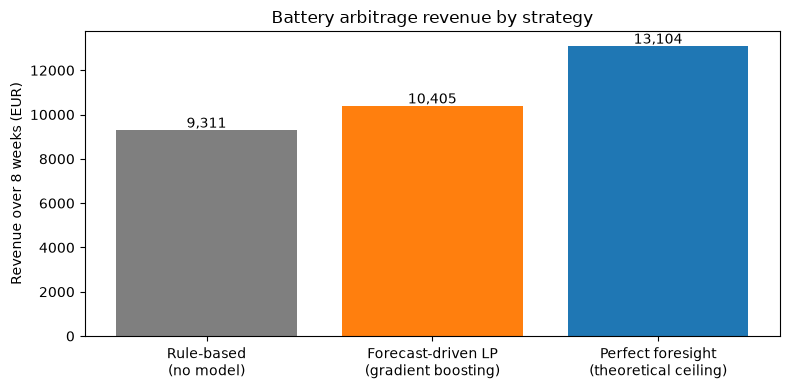

In [3]:
import matplotlib.pyplot as plt

revenues = {
    "Rule-based\n(no model)": rule_revenue,
    "Forecast-driven LP\n(gradient boosting)": forecast_driven_revenue,
    "Perfect foresight\n(theoretical ceiling)": perfect_revenue,
}

plt.figure(figsize=(8, 4))
bars = plt.bar(revenues.keys(), revenues.values(), color=["tab:gray", "tab:orange", "tab:blue"])
plt.ylabel("Revenue over 8 weeks (EUR)")
plt.title("Battery arbitrage revenue by strategy")
for bar, value in zip(bars, revenues.values()):
    plt.text(bar.get_x() + bar.get_width() / 2, value + 100, f"{value:,.0f}", ha="center")
plt.tight_layout()
plt.show()